In [6]:
!pip install -q kagglehub

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

'pip' is not recognized as an internal or external command,
operable program or batch file.


ModuleNotFoundError: No module named 'tensorflow'

In [1]:
# Download dataset from Kaggle

dataset_path = kagglehub.dataset_download(
    "salmaneunus/rock-classification"
)
print("Dataset Downloaded Successfully!")
print("Dataset Location:", dataset_path)

# Find the directory containing class folders

root = Path(dataset_path)
def find_image_root(path):
    extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
    for folder in [path] + list(path.rglob("*")):
        if not folder.is_dir():
            continue
        class_folders = [
            d for d in folder.iterdir() if d.is_dir()
        ]
        valid_classes = [
            d for d in class_folders
            if any(
                f.suffix.lower() in extensions
                for f in d.rglob("*")
                if f.is_file()
            )
        ]
        if len(valid_classes) >= 2:
            return folder
    raise ValueError("Could not find class folders.")
DATA_DIR = find_image_root(root)

print("Image Directory:", DATA_DIR)
print("Rock Categories:")
for folder in DATA_DIR.iterdir():
    if folder.is_dir():
        print(folder.name)

NameError: name 'kagglehub' is not defined

In [4]:
# Collect image paths and labels

extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
class_names = sorted([
    d.name for d in DATA_DIR.iterdir()
    if d.is_dir()
])

class_map = {
    name: i for i, name in enumerate(class_names)
}
image_paths = []
image_labels = []

for name in class_names:
    folder = DATA_DIR / name

    for file in folder.rglob("*"):
        if file.is_file() and file.suffix.lower() in extensions:
            image_paths.append(str(file))
            image_labels.append(class_map[name])
X = np.array(image_paths)
y = np.array(image_labels)

NUM_CLASSES = len(class_names)
print("Total Images:", len(X))
print("Total Classes:", NUM_CLASSES)
print("Classes:", class_names)

# Split into training and temporary data

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split temporary data into validation and testing

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nTraining Images:", len(X_train))
print("Validation Images:", len(X_val))
print("Testing Images:", len(X_test))

# Image preprocessing

IMG_SIZE = 64
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(
        image, [IMG_SIZE, IMG_SIZE]
    )
    image = image / 255.0
    return image, label

def create_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    if training:
        ds = ds.shuffle(1000)
    return ds.batch(BATCH_SIZE).prefetch(
        tf.data.AUTOTUNE
    )
train_ds = create_dataset(X_train, y_train, True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

print("Data Preprocessing Completed!")

Total Images: 2076
Total Classes: 3
Classes: ['Igneous', 'Metamorphic', 'Sedimentary']

Training Images: 1453
Validation Images: 311
Testing Images: 312
Data Preprocessing Completed!


#CNN (Convolutional Neural Network)

In [5]:
cnn_model = models.Sequential([

    layers.Input(shape=(64, 64, 3)),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),

    layers.Dense(NUM_CLASSES, activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

# Training CNN

history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        EarlyStopping(
            patience=3,
            restore_best_weights=True
        )
    ]
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,587 (2.61 MB)

 Trainable params: 683,587 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 34s 378ms/step - accuracy: 0.5994 - loss: 0.8683 - val_accuracy: 0.6592 - val_loss: 0.8083
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 80ms/step - accuracy: 0.6524 - loss: 0.8035 - val_accuracy: 0.6720 - val_loss: 0.7757
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 9s 138ms/step - accuracy: 0.6635 - loss: 0.7808 - val_accuracy: 0.6495 - val_loss: 0.7818
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.6641 - loss: 0.7603 - val_accuracy: 0.6592 - val_loss: 0.7522
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.6635 - loss: 0.7507 - val_accuracy: 0.6688 - val_loss: 0.7749
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 6s 72ms/step - accuracy: 0.6772 - loss: 0.7465 - val_accuracy: 0.6399 - val_loss: 0.8018
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - accuracy: 0.6910 - loss: 0.7017 - val_accuracy: 0.6720 - val_loss: 0.7319
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - accuracy: 0.6999 - loss: 0.6607 - val_accuracy: 0.6817

#ANN (Artificial Neural Network)

In [6]:
ann_model = models.Sequential([

    layers.Input(shape=(64, 64, 3)),

    layers.Flatten(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(64, activation='relu'),

    layers.Dense(NUM_CLASSES, activation='softmax')
])

ann_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

ann_model.summary()

# Training ANN

history_ann = ann_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        EarlyStopping(
            patience=3,
            restore_best_weights=True
        )
    ]
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,187,331 (12.16 MB)

 Trainable params: 3,187,331 (12.16 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 12s 142ms/step - accuracy: 0.4288 - loss: 2.4026 - val_accuracy: 0.4212 - val_loss: 1.0266
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 15s 68ms/step - accuracy: 0.4625 - loss: 1.0297 - val_accuracy: 0.5145 - val_loss: 0.9272
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 113ms/step - accuracy: 0.5003 - loss: 0.9621 - val_accuracy: 0.4952 - val_loss: 0.9269
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.5093 - loss: 0.9408 - val_accuracy: 0.5627 - val_loss: 0.8963
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 68ms/step - accuracy: 0.4942 - loss: 0.9557 - val_accuracy: 0.5370 - val_loss: 0.8932
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step - accuracy: 0.5237 - loss: 0.9277 - val_accuracy: 0.5434 - val_loss: 0.9150
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 67ms/step - accuracy: 0.5306 - loss: 0.9220 - val_accuracy: 0.5145 - val_loss: 0.9251
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - accuracy: 0.5038 - loss: 0.9226 - val_accuracy: 0.49

#RNN (Recurrent Neural Network using LSTM)

In [7]:
rnn_model = models.Sequential([

    layers.Input(shape=(64, 64 * 3)),

    layers.LSTM(64),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.4),

    layers.Dense(NUM_CLASSES, activation='softmax')
])

rnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

rnn_model.summary()

# Convert images into row sequences

def make_rnn_dataset(ds):

    return ds.map(
        lambda x, y: (
            tf.reshape(x, [-1, 64, 192]),
            y
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

train_rnn = make_rnn_dataset(train_ds)
val_rnn = make_rnn_dataset(val_ds)
test_rnn = make_rnn_dataset(test_ds)

# Training RNN

history_rnn = rnn_model.fit(
    train_rnn,
    validation_data=val_rnn,
    epochs=10,
    callbacks=[
        EarlyStopping(
            patience=3,
            restore_best_weights=True
        )
    ]
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,499 (291.01 KB)

 Trainable params: 74,499 (291.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.4825 - loss: 0.9574 - val_accuracy: 0.5080 - val_loss: 0.9185
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.5169 - loss: 0.9050 - val_accuracy: 0.4952 - val_loss: 0.9037
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step - accuracy: 0.5127 - loss: 0.9025 - val_accuracy: 0.5177 - val_loss: 0.8846
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 6s 74ms/step - accuracy: 0.5327 - loss: 0.8842 - val_accuracy: 0.5531 - val_loss: 0.8713
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 10s 71ms/step - accuracy: 0.5588 - loss: 0.8670 - val_accuracy: 0.5305 - val_loss: 0.8882
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 11s 74ms/step - accuracy: 0.5623 - loss: 0.8577 - val_accuracy: 0.5949 - val_loss: 0.8465
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 86ms/step - accuracy: 0.5891 - loss: 0.8458 - val_accuracy: 0.5788 - val_loss: 0.8554
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.6029 - loss: 0.8291 - val_accuracy: 0.5788

#Testing and Performance Evaluation


CNN PERFORMANCE
              precision    recall  f1-score   support

     Igneous       0.00      0.00      0.00        28
 Metamorphic       0.63      0.78      0.70       130
 Sedimentary       0.69      0.67      0.68       154

    accuracy                           0.66       312
   macro avg       0.44      0.48      0.46       312
weighted avg       0.60      0.66      0.63       312



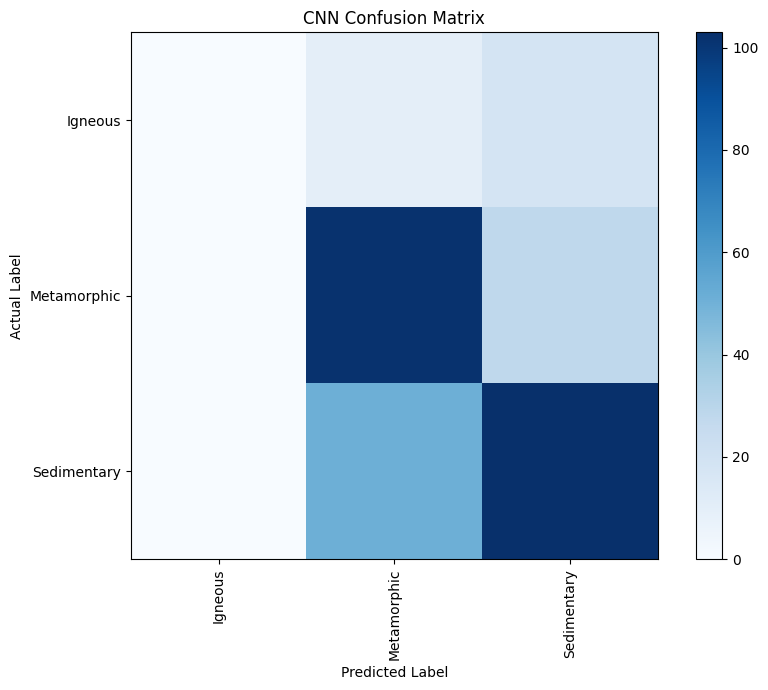


ANN PERFORMANCE
              precision    recall  f1-score   support

     Igneous       0.00      0.00      0.00        28
 Metamorphic       0.52      0.67      0.58       130
 Sedimentary       0.57      0.53      0.55       154

    accuracy                           0.54       312
   macro avg       0.36      0.40      0.38       312
weighted avg       0.50      0.54      0.51       312



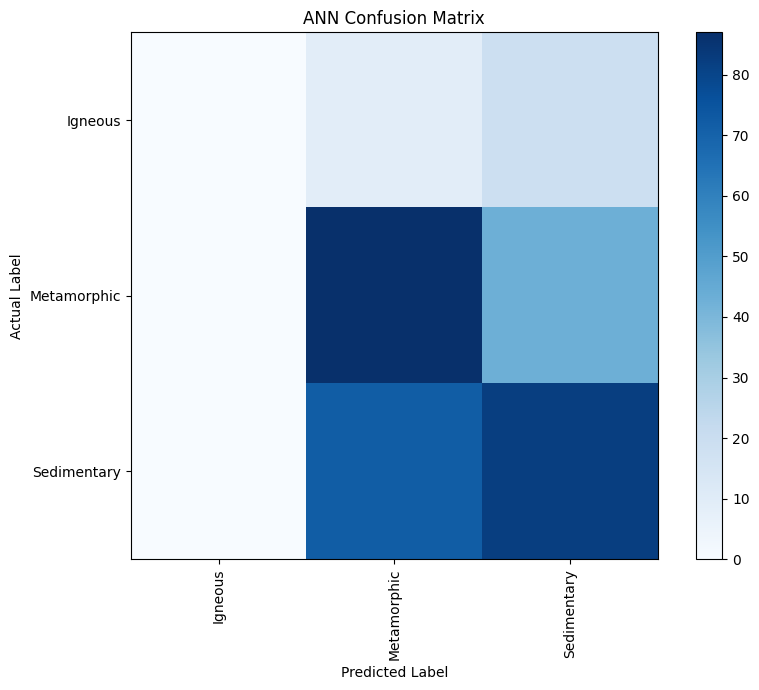


RNN PERFORMANCE
              precision    recall  f1-score   support

     Igneous       0.00      0.00      0.00        28
 Metamorphic       0.55      0.73      0.62       130
 Sedimentary       0.66      0.59      0.62       154

    accuracy                           0.60       312
   macro avg       0.40      0.44      0.42       312
weighted avg       0.55      0.60      0.57       312



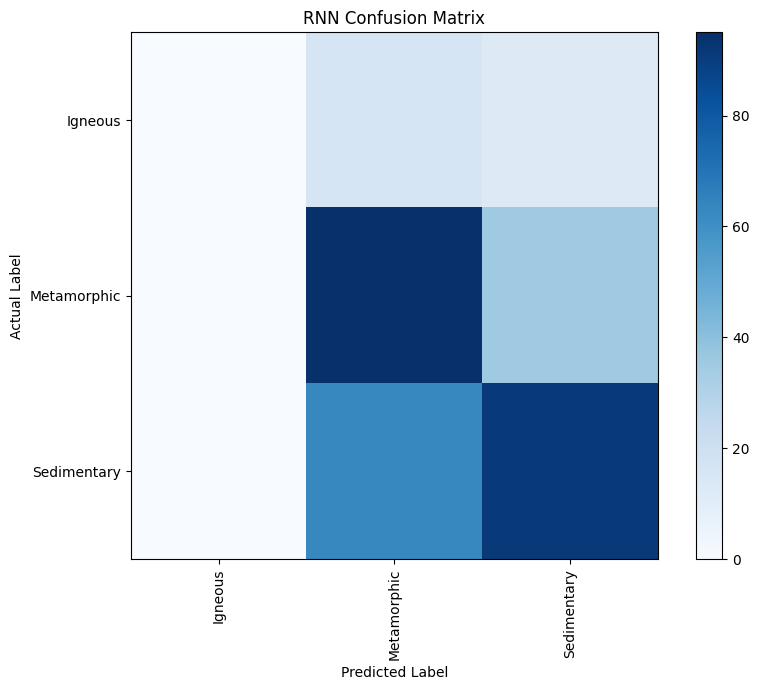


FINAL PERFORMANCE COMPARISON


,Algorithm,Test Loss,Accuracy,Precision,Recall,F1 Score
0,CNN,0.7909,0.6571,0.6019,0.6571,0.6257
1,ANN,0.9039,0.5417,0.4968,0.5417,0.5149
2,RNN,0.8389,0.5962,0.5530,0.5962,0.5681


In [8]:
models_dict = {
    "CNN": (cnn_model, test_ds),
    "ANN": (ann_model, test_ds),
    "RNN": (rnn_model, test_rnn)
}

results = []

for name, (model, dataset) in models_dict.items():

    # Get actual labels
    y_true = np.concatenate([
        labels.numpy()
        for _, labels in dataset
    ])

    # Predict labels
    predictions = model.predict(dataset, verbose=0)
    y_pred = np.argmax(predictions, axis=1)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_true, y_pred,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred,
        average='weighted',
        zero_division=0
    )

    loss, test_accuracy = model.evaluate(
        dataset, verbose=0
    )

    results.append({
        "Algorithm": name,
        "Test Loss": loss,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("\n", "="*50)
    print(name, "PERFORMANCE")
    print("="*50)

    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        zero_division=0
    ))

    # Confusion Matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    plt.figure(figsize=(9, 7))

    plt.imshow(cm, cmap='Blues')
    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")

    plt.xticks(range(NUM_CLASSES), class_names,
               rotation=90)
    plt.yticks(range(NUM_CLASSES), class_names)

    plt.colorbar()
    plt.tight_layout()
    plt.show()

# Final performance table

results_df = pd.DataFrame(results)

print("\nFINAL PERFORMANCE COMPARISON")

display(
    results_df.round(4)
)

#Graphs and Final Algorithm Comparison

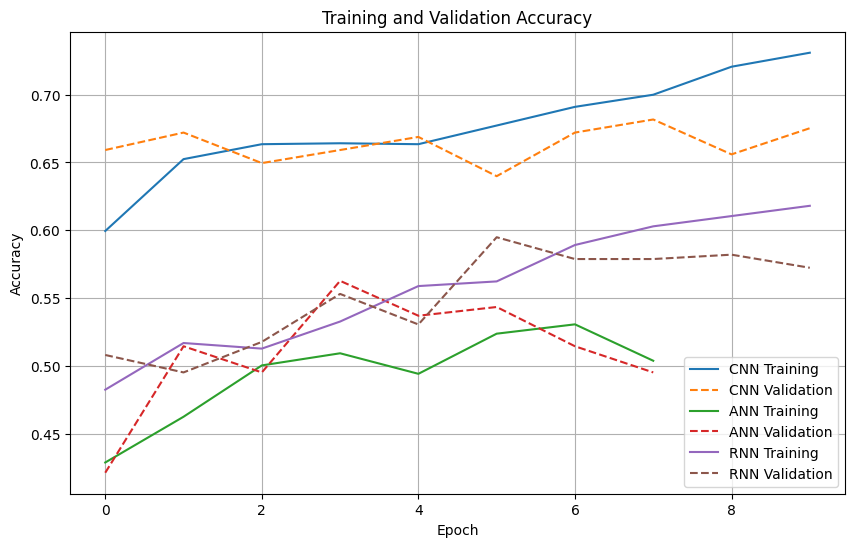

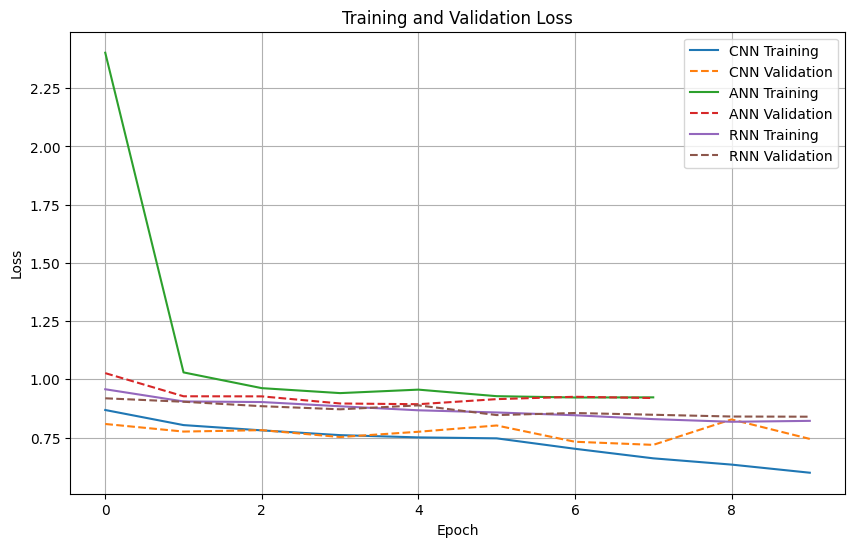

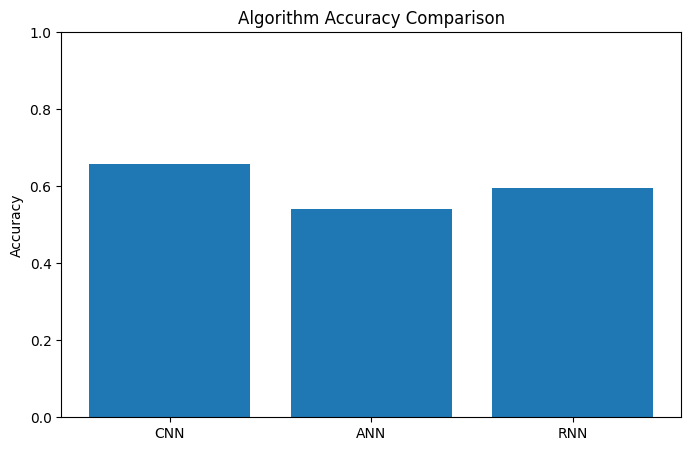

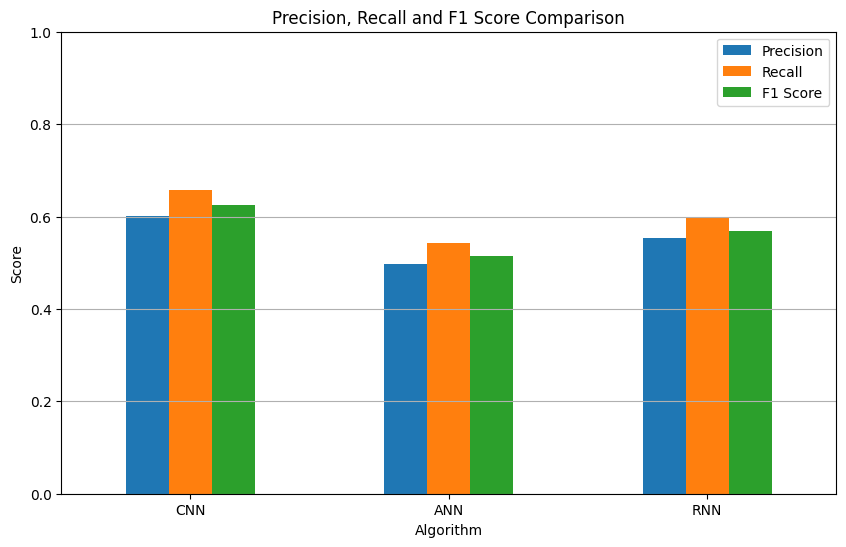


========== FINAL RESULT ==========
Best Algorithm: CNN
Accuracy: 65.71 %
Precision: 60.19 %
Recall: 65.71 %
F1 Score: 62.57 %

Complete Comparison:


,Algorithm,Test Loss,Accuracy,Precision,Recall,F1 Score
0,CNN,0.7909,0.6571,0.6019,0.6571,0.6257
1,ANN,0.9039,0.5417,0.4968,0.5417,0.5149
2,RNN,0.8389,0.5962,0.5530,0.5962,0.5681


In [9]:
histories = {
    "CNN": history_cnn,
    "ANN": history_ann,
    "RNN": history_rnn
}

# 1. Training and Validation Accuracy
plt.figure(figsize=(10, 6))
for name, history in histories.items():
    plt.plot(
        history.history['accuracy'],
        label=name + " Training"
    )
    plt.plot(
        history.history['val_accuracy'],
        linestyle='--',
        label=name + " Validation"
    )
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# 2. Training and Validation Loss
plt.figure(figsize=(10, 6))
for name, history in histories.items():
    plt.plot(
        history.history['loss'],
        label=name + " Training"
    )
    plt.plot(
        history.history['val_loss'],
        linestyle='--',
        label=name + " Validation"
    )
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

# 3. Accuracy Comparison
plt.figure(figsize=(8, 5))
plt.bar(
    results_df["Algorithm"],
    results_df["Accuracy"]
)
plt.title("Algorithm Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

# 4. Precision, Recall and F1 Score Comparison
results_df.set_index("Algorithm")[
    ["Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10, 6)
)
plt.title("Precision, Recall and F1 Score Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

# 5. Identify Best Algorithm
best_model = results_df.loc[
    results_df["Accuracy"].idxmax()
]
print("\n========== FINAL RESULT ==========")
print("Best Algorithm:", best_model["Algorithm"])
print("Accuracy:", round(best_model["Accuracy"] * 100, 2), "%")
print("Precision:", round(best_model["Precision"] * 100, 2), "%")
print("Recall:", round(best_model["Recall"] * 100, 2), "%")
print("F1 Score:", round(best_model["F1 Score"] * 100, 2), "%")
print("\nComplete Comparison:")
display(results_df.round(4))

#ROC Curve

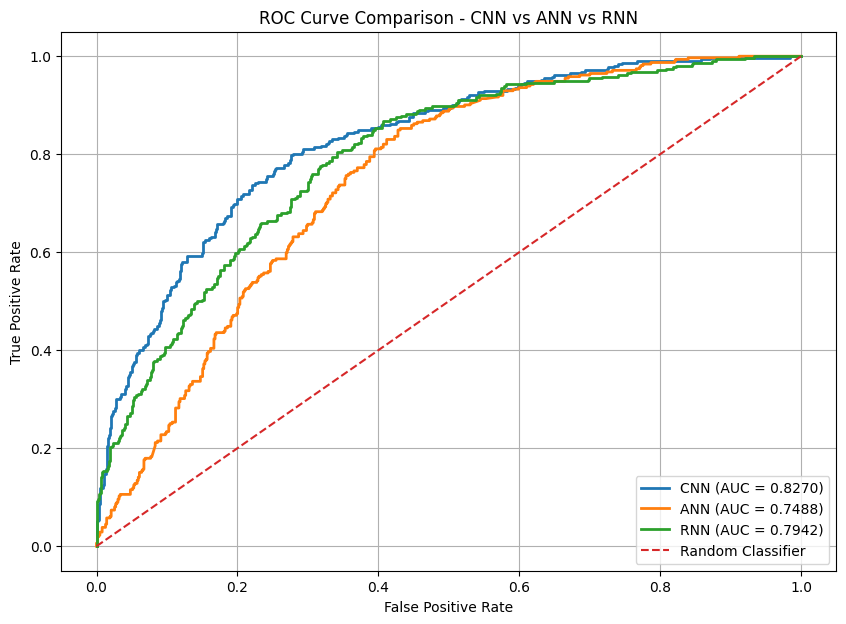


========== ROC-AUC COMPARISON ==========
CNN AUC Score: 0.827
ANN AUC Score: 0.7488
RNN AUC Score: 0.7942

Best Algorithm Based on AUC: CNN


In [11]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Dictionary containing models and test datasets

models_roc = {
    "CNN": (cnn_model, test_ds),
    "ANN": (ann_model, test_ds),
    "RNN": (rnn_model, test_rnn)
}

# Convert actual labels into one-hot format

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(NUM_CLASSES)
)

auc_results = {}
plt.figure(figsize=(10, 7))

# Calculate ROC Curve for each algorithm

for name, (model, dataset) in models_roc.items():
    y_prob = model.predict(dataset, verbose=0)

    # Calculate micro-average ROC curve
    fpr, tpr, thresholds = roc_curve(
        y_test_binary.ravel(),
        y_prob.ravel()
    )

    roc_auc = auc(fpr, tpr)
    auc_results[name] = roc_auc

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {roc_auc:.4f})"
    )

# Random classifier reference line

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title("ROC Curve Comparison - CNN vs ANN vs RNN")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend(loc="lower right")
plt.grid()
plt.show()


# Display AUC Comparison

print("\n========== ROC-AUC COMPARISON ==========")

for name, score in auc_results.items():
    print(name, "AUC Score:", round(score, 4))

best_roc = max(auc_results, key=auc_results.get)

print("\nBest Algorithm Based on AUC:", best_roc)